# Does a model of a delayed response need correctly timed features?

| | |
| --- | --- |
| **Question** | When a measured response is a delayed and smoothed copy of the stimulus features, how much does held-out prediction depend on modeling that delay and on aligning the features in time? |
| **Requires** | CPU only. No downloads. Synthetic data only. About 5 seconds. |
| **Lessons used** | None of the numbered lessons is required. Feature timestamps follow the conventions in [1. Your first subject](../lessons/01_your_first_subject.ipynb). |

## Background

fMRI measures the blood-oxygen (BOLD) signal, which follows neural activity with a delay of about 5 seconds and is smeared over 10 to 20 seconds. The standard model of this delay is the hemodynamic response function (HRF). The scanner samples the brain once per repetition time (TR), typically every 1 to 2 seconds.

Model features arrive at their own rates, for example one vector per video frame and one per audio window. Before features can predict BOLD they must be placed on the TR clock and convolved with the HRF. If either step is wrong, an encoding model can fail even when the features contain the right information.

## Hypothesis

For a response built from HRF-convolved features, a linear fit on the raw features will predict held-out data poorly, and a fit on HRF-convolved features will predict it well. Shifting the convolved features away from their correct timing will reduce held-out prediction, but gradually rather than at once, because the HRF makes neighboring samples similar.

## Method

The experiment has three steps. First, two feature streams with different native rates are resampled onto a common TR grid. Second, the HRF is applied to a single impulse to show the delay it introduces. Third, a synthetic response is built from HRF-convolved features, and held-out prediction is measured with raw features, with convolved features, and with convolved features shifted in time.

The response in step three is constructed from the features, so a correctly specified model must fit it. This makes it a positive control: it tests the analysis, not a brain.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import matplotlib.pyplot as plt
import numpy as np
from brainscore_core.supported_data_standards.brainio.assemblies import NeuroidAssembly
from brainscore.temporal import synchronize_modalities, hrf_convolve
from brainscore_core.nulls import temporal_shift_curve

Step 1: a common clock. The video stream has 250 ms bins and the audio stream has 500 ms bins. In bin number b each stream holds the value b times a constant, so the resampled values can be checked by hand. `synchronize_modalities` averages the source bins whose centers fall in each 500 ms target bin and concatenates the two streams along the feature axis.

In [2]:
def stream(n_clips, bins, n_features, scale):
    """A synthetic feature stream whose value in bin b is b * scale."""
    data = np.stack([np.full((n_clips, n_features), b * scale) for b in range(len(bins))], axis=1)
    ids = [f'c{i}' for i in range(n_clips)]
    return NeuroidAssembly(data, dims=['presentation', 'time_bin', 'neuroid'], coords={
        'clip_id': ('presentation', ids),
        'stimulus_id': ('presentation', ids),
        'time_bin_start_ms': ('time_bin', [start for start, _ in bins]),
        'time_bin_end_ms': ('time_bin', [end for _, end in bins]),
        'neuroid_id': ('neuroid', np.arange(n_features)),
        'layer': ('neuroid', ['L'] * n_features),
    })


video = stream(3, [(0, 250), (250, 500), (500, 750), (750, 1000)], 4, 1.0)
audio = stream(3, [(0, 500), (500, 1000)], 6, 10.0)
merged = synchronize_modalities({'video': video, 'audio': audio}, [(0, 500), (500, 1000)])
print('Merged sizes:', dict(merged.sizes))
for modality in ['video', 'audio']:
    values = merged.values[0][:, merged['modality'].values == modality][:, 0]
    print(f'{modality} values in the two TR bins: {values.tolist()}')

Merged sizes: {'presentation': 3, 'time_bin': 2, 'neuroid': 10}
video values in the two TR bins: [0.5, 2.5]
audio values in the two TR bins: [0.0, 10.0]


Step 2: the delay. Convolve a single impulse at sample 10 with the HRF, sampled at 1 Hz (one sample per second), and find the peak of the response.

In [3]:
impulse = np.zeros((40, 1))
impulse[10] = 1.0
response = hrf_convolve(impulse, sampling_rate_hz=1.0)[:, 0]
peak = int(np.argmax(response))
print(f'Impulse at t = 10 s; response peaks at t = {peak} s ({peak - 10} s later).')

Impulse at t = 10 s; response peaks at t = 15 s (5 s later).


Step 3: the alignment test. Build 240 samples (one per second) of 6 random features and a 4-dimensional response equal to the HRF-convolved features times fixed weights, plus noise at 10% of the response standard deviation. The fit uses ridge regression on the first 120 samples and reports the mean Pearson correlation between prediction and response on the last 120 samples.

In [4]:
rng = np.random.RandomState(0)
X_raw = rng.randn(240, 6)
X_hrf = hrf_convolve(X_raw, sampling_rate_hz=1.0)
W = rng.randn(6, 4)
Y = X_hrf @ W
Y = Y + 0.1 * Y.std() * rng.randn(*Y.shape)


def held_out_r(X):
    """Ridge fit on the first half; mean Pearson r over response dimensions on the second half."""
    train, test = slice(0, 120), slice(120, 240)
    y_mean = Y[train].mean(axis=0)
    weights = np.linalg.solve(X[train].T @ X[train] + np.eye(X.shape[1]),
                              X[train].T @ (Y[train] - y_mean))
    prediction = X[test] @ weights + y_mean
    return float(np.mean([np.corrcoef(prediction[:, j], Y[test, j])[0, 1] for j in range(4)]))

Shift each feature matrix by whole samples and refit at every shift. A positive shift delays the features. `temporal_shift_curve` uses a circular shift, so every sample is used at every shift.

In [5]:
SHIFTS = list(range(-10, 11))
curve_hrf = temporal_shift_curve(held_out_r, X_hrf, SHIFTS)
curve_raw = temporal_shift_curve(held_out_r, X_raw, SHIFTS)

## Results

Raw features, no shift:           r = 0.05
HRF-convolved features, no shift: r = 0.98
Raw features, best shift:         r = 0.44 at a delay of 5 s


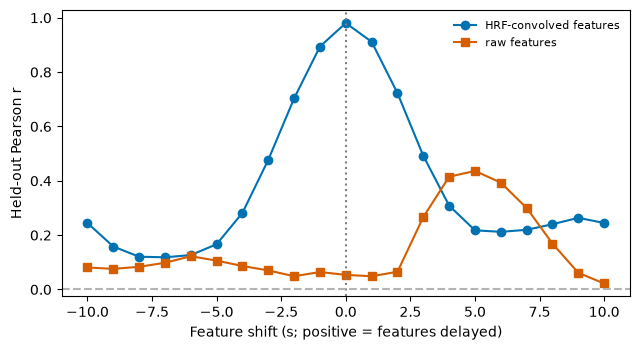

{-10: 0.24, -3: 0.48, -1: 0.89, 0: 0.98, 1: 0.91, 3: 0.49, 10: 0.24}


In [6]:
print(f'Raw features, no shift:           r = {curve_raw[0]:.2f}')
print(f'HRF-convolved features, no shift: r = {curve_hrf[0]:.2f}')
best_raw = max(curve_raw, key=curve_raw.get)
print(f'Raw features, best shift:         r = {curve_raw[best_raw]:.2f} at a delay of {best_raw} s')

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(SHIFTS, [curve_hrf[s] for s in SHIFTS], 'o-', color='#0072B2', label='HRF-convolved features')
ax.plot(SHIFTS, [curve_raw[s] for s in SHIFTS], 's-', color='#D55E00', label='raw features')
ax.axvline(0, ls=':', c='0.5')
ax.axhline(0, ls='--', c='0.7')
ax.set_xlabel('Feature shift (s; positive = features delayed)')
ax.set_ylabel('Held-out Pearson r')
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

print({s: round(curve_hrf[s], 2) for s in [-10, -3, -1, 0, 1, 3, 10]})

The common clock averages the two 250 ms video bins in each 500 ms TR bin (0.5 and 2.5) and passes the audio bins through unchanged (0 and 10). The HRF moves an impulse at 10 s to a peak at 15 s.

With correct timing, HRF-convolved features predict the held-out response with r = 0.98, and raw features give r = 0.05. Delaying the raw features by 5 s, the HRF peak delay, raises r to 0.44. Shifting the convolved features by 1 s lowers r to about 0.9, by 3 s to about 0.48, and by 10 s to 0.24, rather than to zero.

## Conclusion and limits

When the response is a delayed and smoothed copy of the features, raw features predict it poorly, and HRF-convolved features predict it well. A pure delay of the raw features recovers part of the signal, with the best delay near the HRF peak, but it does not reproduce the smoothing. Misaligning the convolved features reduces prediction gradually, because convolution makes neighboring samples correlated.

This last point matters for real data. A correlation that survives a shift of a few TRs does not by itself show that the model is wrong, and a correlation that is high at zero shift does not by itself show that the features are time-locked to the brain. Slow signals and autocorrelation must be controlled, for example with contiguous-block cross-validation.

All data here are synthetic, the HRF is the canonical one, and the response is constructed from the features. Real BOLD responses vary in shape across regions and people.

Back to the [notebook index](../README.md) and the [documentation](../../docs/README.md).